In [ ]:
import os
from pathlib import Path

# notebook lives in <project>/notebooks, so the project root is one level up
PROJECT_ROOT = str(Path.cwd().parent) if Path.cwd().name == 'notebooks' else str(Path.cwd())

In [3]:
print(os.path.exists(PROJECT_ROOT))
print(os.listdir(PROJECT_ROOT))

True
['checkpoints', 'Data', 'Documentation', 'notebooks', 'submissions']


In [4]:
DATA_ROOT = os.path.join(PROJECT_ROOT, 'data', 'filament-segmentation-2026',
                         'MAGFiLO_1.0_Kaggle_2026')
print(os.path.exists(DATA_ROOT))
print(os.listdir(DATA_ROOT))

True
['test', 'train']


In [5]:
print(os.listdir(f'{DATA_ROOT}/train'))
print(os.listdir(f'{DATA_ROOT}/test'))
print(len(os.listdir(f'{DATA_ROOT}/train/train_images')))

['MAGFiLO_1.0_Annotations_kaggle2026_train.json', 'train_images']
['test_images']
707


In [6]:
import json

with open(f'{DATA_ROOT}/train/MAGFiLO_1.0_Annotations_kaggle2026_train.json') as f:
    coco_data = json.load(f)

print(coco_data.keys())
print("Num images:", len(coco_data['images']))
print("Num annotations:", len(coco_data['annotations']))
print("Categories:", coco_data['categories'])

dict_keys(['info', 'licenses', 'categories', 'images', 'annotations'])
Num images: 1154
Num annotations: 8199
Categories: [{'supercategory': 'filament', 'id': 1, 'name': 'Left'}, {'supercategory': 'filament', 'id': 2, 'name': 'Right'}, {'supercategory': 'filament', 'id': 3, 'name': 'Unidentifiable'}, {'supercategory': 'filament', 'id': 4, 'name': 'Ambiguous'}]


In [7]:
import numpy as np

images_by_id = {img['id']: img for img in coco_data['images']}

anns_by_image_id = {}
for ann in coco_data['annotations']:
    anns_by_image_id.setdefault(ann['image_id'], []).append(ann)

counts = [len(v) for v in anns_by_image_id.values()]
print("Avg filaments/image-annotation:", np.mean(counts))
print("Max:", np.max(counts), "Min:", np.min(counts))

Avg filaments/image-annotation: 7.104852686308492
Max: 26 Min: 1


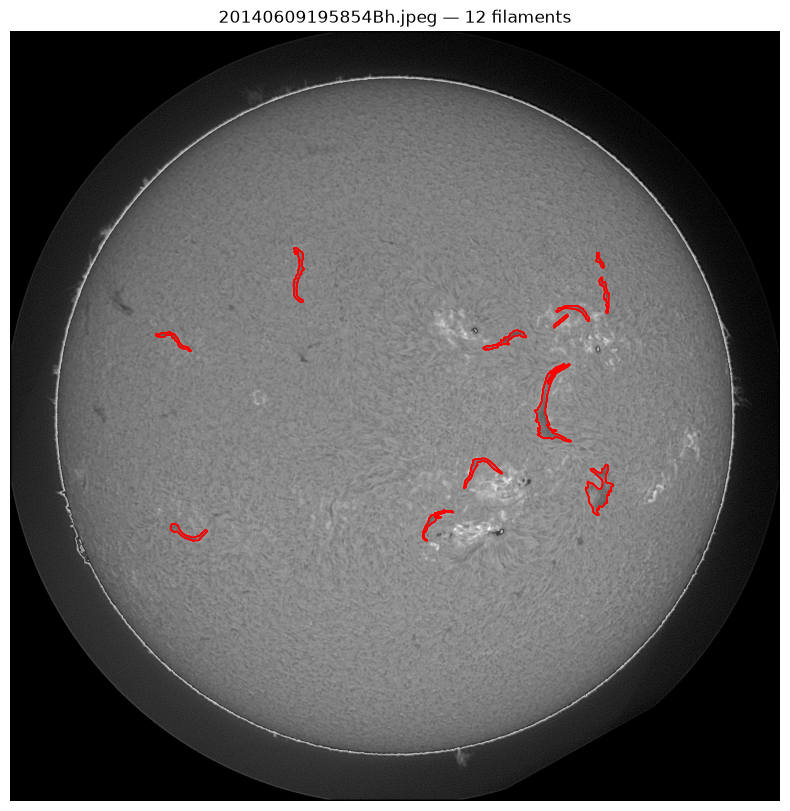

In [8]:
from pycocotools import mask as maskUtils
from PIL import Image
import matplotlib.pyplot as plt

def polygon_to_mask(segmentation, height, width):
    rles = maskUtils.frPyObjects(segmentation, height, width)
    rle = maskUtils.merge(rles)
    return maskUtils.decode(rle)

sample_image_id = coco_data['images'][0]['id']
img_info = images_by_id[sample_image_id]
img_path = f"{DATA_ROOT}/train/train_images/{img_info['file_name']}"

img = np.array(Image.open(img_path).convert('L'))
anns = anns_by_image_id.get(sample_image_id, [])

fig, ax = plt.subplots(figsize=(10, 10))
ax.imshow(img, cmap='gray')

for ann in anns:
    mask = polygon_to_mask(ann['segmentation'], img_info['height'], img_info['width'])
    ax.contour(mask, colors='red', linewidths=0.8)

ax.set_title(f"{img_info['file_name']} — {len(anns)} filaments")
plt.axis('off')
plt.show()

Bbox width  — mean: 103.2195853762654 median: 74.52260000000001 max: 1067.3136
Bbox height — mean: 91.78958944993292 median: 69.60519999999997 max: 709.8073999999999
Area — mean: 2119.8349798755944 median: 1228.0


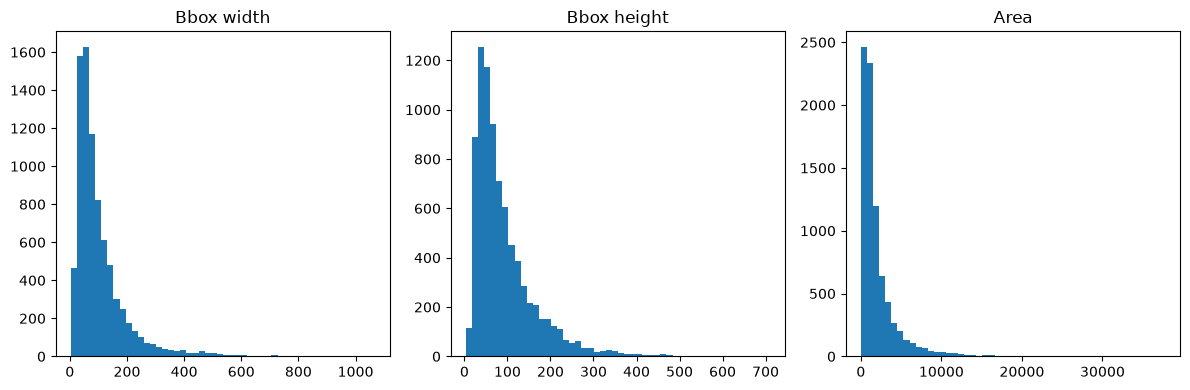

In [9]:
widths, heights, areas = [], [], []
for ann in coco_data['annotations']:
    x, y, w, h = ann['bbox']
    widths.append(w)
    heights.append(h)
    areas.append(ann['area'])

print("Bbox width  — mean:", np.mean(widths), "median:", np.median(widths), "max:", np.max(widths))
print("Bbox height — mean:", np.mean(heights), "median:", np.median(heights), "max:", np.max(heights))
print("Area — mean:", np.mean(areas), "median:", np.median(areas))

plt.figure(figsize=(12, 4))
plt.subplot(1, 3, 1); plt.hist(widths, bins=50); plt.title("Bbox width")
plt.subplot(1, 3, 2); plt.hist(heights, bins=50); plt.title("Bbox height")
plt.subplot(1, 3, 3); plt.hist(areas, bins=50); plt.title("Area")
plt.tight_layout()
plt.show()

In [10]:
widths_arr = np.array(widths)
heights_arr = np.array(heights)

for p in [50, 75, 90, 95, 99]:
    print(f"p{p} — width: {np.percentile(widths_arr, p):.1f}, height: {np.percentile(heights_arr, p):.1f}")

for crop_size in [256, 384, 512, 768]:
    margin = crop_size * 0.8
    fits = np.mean((widths_arr < margin) & (heights_arr < margin)) * 100
    print(f"Crop {crop_size}px: {fits:.1f}% of filaments fit fully")

p50 — width: 74.5, height: 69.6
p75 — width: 126.2, height: 116.6
p90 — width: 202.5, height: 186.5
p95 — width: 280.9, height: 230.7
p99 — width: 499.1, height: 358.0
Crop 256px: 86.3% of filaments fit fully
Crop 384px: 94.7% of filaments fit fully
Crop 512px: 97.5% of filaments fit fully
Crop 768px: 99.7% of filaments fit fully


In [11]:
from collections import defaultdict

# group image_ids by their underlying physical file
file_to_image_ids = defaultdict(list)
for img in coco_data['images']:
    file_to_image_ids[img['file_name']].append(img['id'])

print("Unique physical files:", len(file_to_image_ids))
print("Total image-id entries:", len(coco_data['images']))

# how many files have multiple annotator versions?
multi = {k: v for k, v in file_to_image_ids.items() if len(v) > 1}
print("Files with multiple annotation sets:", len(multi))

Unique physical files: 707
Total image-id entries: 1154
Files with multiple annotation sets: 296


In [12]:
np.random.seed(42)
unique_files = list(file_to_image_ids.keys())
np.random.shuffle(unique_files)

n_val = int(len(unique_files) * 0.15)
val_files = set(unique_files[:n_val])
train_files = set(unique_files[n_val:])

train_image_ids = [iid for f in train_files for iid in file_to_image_ids[f]]
val_image_ids = [iid for f in val_files for iid in file_to_image_ids[f]]

print(f"Train: {len(train_files)} files / {len(train_image_ids)} image-ids")
print(f"Val:   {len(val_files)} files / {len(val_image_ids)} image-ids")

Train: 601 files / 993 image-ids
Val:   106 files / 161 image-ids


In [13]:
import numpy as np

TILE_SIZE = 512
STRIDE = 384  # 512 - 128 overlap

def generate_tile_coords(img_width, img_height, tile_size=TILE_SIZE, stride=STRIDE):
    """Returns list of (x0, y0) top-left corners covering the full image, including edges."""
    coords = []
    xs = list(range(0, img_width - tile_size + 1, stride))
    ys = list(range(0, img_height - tile_size + 1, stride))
    # ensure right/bottom edges are covered even if stride doesn't divide evenly
    if xs[-1] + tile_size < img_width:
        xs.append(img_width - tile_size)
    if ys[-1] + tile_size < img_height:
        ys.append(img_height - tile_size)
    for y0 in ys:
        for x0 in xs:
            coords.append((x0, y0))
    return coords

# sanity check on one image
tiles = generate_tile_coords(2048, 2048)
print("Num tiles per image:", len(tiles))
print(tiles[:5])

Num tiles per image: 25
[(0, 0), (384, 0), (768, 0), (1152, 0), (1536, 0)]


In [14]:
from shapely.geometry import Polygon, MultiPolygon, box

def clip_annotation_to_tile(segmentation, x0, y0, tile_size):
    coords = list(zip(segmentation[0::2], segmentation[1::2]))
    poly = Polygon(coords)
    if not poly.is_valid:
        poly = poly.buffer(0)

    tile_box = box(x0, y0, x0 + tile_size, y0 + tile_size)
    clipped = poly.intersection(tile_box)

    if clipped.is_empty:
        return []

    if clipped.geom_type == 'Polygon':
        polys = [clipped]
    elif clipped.geom_type == 'MultiPolygon':
        polys = list(clipped.geoms)
    elif clipped.geom_type == 'GeometryCollection':
        polys = [g for g in clipped.geoms if g.geom_type == 'Polygon']
    else:
        # Point, LineString, MultiLineString — no area, skip
        return []

    result = []
    for p in polys:
        if p.is_empty or p.area < 4:
            continue
        local_coords = [(px - x0, py - y0) for px, py in p.exterior.coords]
        result.append(local_coords)
    return result

In [15]:
import torch
from torch.utils.data import Dataset
from pycocotools import mask as maskUtils

class FilamentTileDataset(Dataset):
    def __init__(self, image_ids, coco_data, images_by_id, anns_by_image_id,
                 image_dir, tile_size=512, stride=384, skip_empty_prob=0.7):
        """
        skip_empty_prob: probability of DROPPING a tile that has zero filaments.
        Keeps some empty tiles (so model learns background) without drowning
        in them, given filaments are sparse per your earlier stats.
        """
        self.image_dir = image_dir
        self.tile_size = tile_size
        self.images_by_id = images_by_id
        self.anns_by_image_id = anns_by_image_id
        self.samples = []  # list of (image_id, x0, y0)

        rng = np.random.RandomState(42)

        for image_id in image_ids:
            img_info = images_by_id[image_id]
            w, h = img_info['width'], img_info['height']
            anns = anns_by_image_id.get(image_id, [])

            for (x0, y0) in generate_tile_coords(w, h, tile_size, stride):
                tile_box_poly = box(x0, y0, x0 + tile_size, y0 + tile_size)
                has_filament = False
                for ann in anns:
                    coords = list(zip(ann['segmentation'][0][0::2], ann['segmentation'][0][1::2])) \
                        if isinstance(ann['segmentation'][0], list) else \
                        list(zip(ann['segmentation'][0::2], ann['segmentation'][1::2]))
                    p = Polygon(coords)
                    if not p.is_valid:
                        p = p.buffer(0)
                    if p.intersects(tile_box_poly):
                        has_filament = True
                        break

                if not has_filament and rng.rand() < skip_empty_prob:
                    continue  # drop most empty tiles

                self.samples.append((image_id, x0, y0))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        image_id, x0, y0 = self.samples[idx]
        img_info = self.images_by_id[image_id]
        anns = self.anns_by_image_id.get(image_id, [])

        img_path = f"{self.image_dir}/{img_info['file_name']}"
        full_img = np.array(Image.open(img_path).convert('L'))
        tile_img = full_img[y0:y0+self.tile_size, x0:x0+self.tile_size]

        mask = np.zeros((self.tile_size, self.tile_size), dtype=np.uint8)
        instance_id = 1
        for ann in anns:
            seg = ann['segmentation'][0] if isinstance(ann['segmentation'][0], list) else ann['segmentation']
            clipped_polys = clip_annotation_to_tile(seg, x0, y0, self.tile_size)
            for local_coords in clipped_polys:
                flat = [c for point in local_coords for c in point]
                rles = maskUtils.frPyObjects([flat], self.tile_size, self.tile_size)
                rle = maskUtils.merge(rles)
                inst_mask = maskUtils.decode(rle)
                mask[inst_mask > 0] = 255  # binary for now; instance ids come later if needed
            instance_id += 1

        img_tensor = torch.from_numpy(tile_img).float().unsqueeze(0) / 255.0
        mask_tensor = torch.from_numpy(mask).float().unsqueeze(0) / 255.0

        return img_tensor, mask_tensor

In [16]:
print(type(coco_data['annotations'][0]['segmentation']))
print(type(coco_data['annotations'][0]['segmentation'][0]))
print(coco_data['annotations'][0]['segmentation'][0][:8])  # first few values

<class 'list'>
<class 'list'>
[480.9382, 850.955, 480.307, 852.0535, 478.2989, 852.451, 476.1202, 851.3087]


In [17]:
train_dataset = FilamentTileDataset(
    image_ids=train_image_ids,
    coco_data=coco_data,
    images_by_id=images_by_id,
    anns_by_image_id=anns_by_image_id,
    image_dir=f"{DATA_ROOT}/train/train_images",
    tile_size=512,
    stride=384,
    skip_empty_prob=0.7
)

val_dataset = FilamentTileDataset(
    image_ids=val_image_ids,
    coco_data=coco_data,
    images_by_id=images_by_id,
    anns_by_image_id=anns_by_image_id,
    image_dir=f"{DATA_ROOT}/train/train_images",
    tile_size=512,
    stride=384,
    skip_empty_prob=0.0  # keep ALL val tiles — don't want to randomly drop val data
)

print("Train tiles:", len(train_dataset))
print("Val tiles:", len(val_dataset))

Train tiles: 14535
Val tiles: 4025


Image tensor: torch.Size([1, 512, 512]) torch.float32 0.0 0.8941176533699036
Mask tensor: torch.Size([1, 512, 512]) torch.float32 0.0 0.0


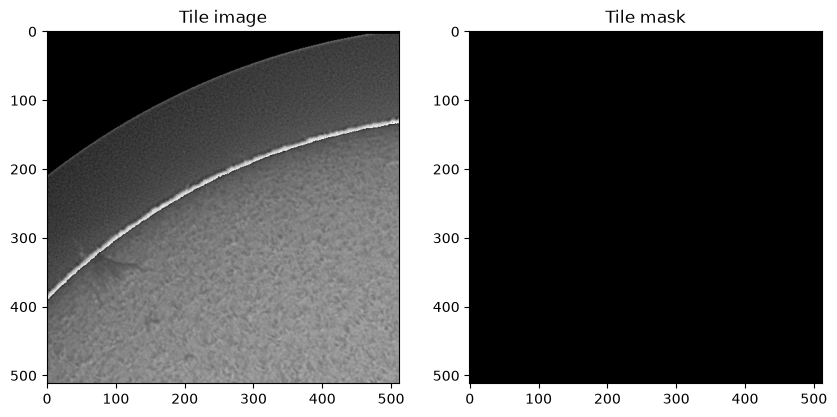

In [18]:
img_t, mask_t = train_dataset[0]
print("Image tensor:", img_t.shape, img_t.dtype, img_t.min().item(), img_t.max().item())
print("Mask tensor:", mask_t.shape, mask_t.dtype, mask_t.min().item(), mask_t.max().item())

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(img_t.squeeze(), cmap='gray')
axes[0].set_title("Tile image")
axes[1].imshow(mask_t.squeeze(), cmap='gray')
axes[1].set_title("Tile mask")
plt.show()

Found non-empty tile at index 2


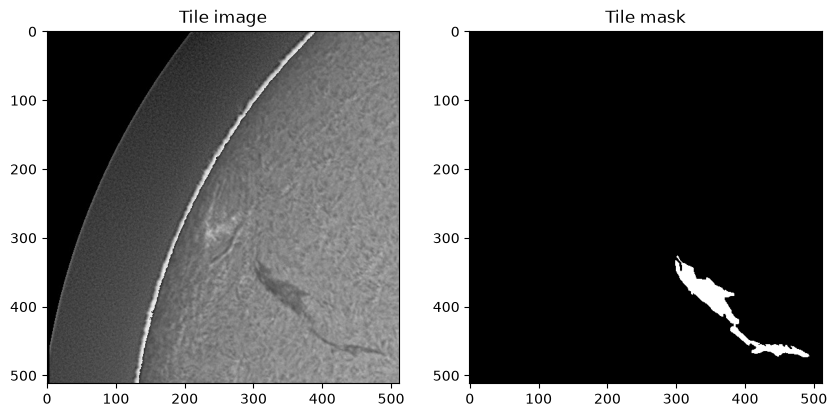

Mask pixel count: 4037


In [19]:
# find a tile with actual filament content
for i in range(len(train_dataset)):
    img_t, mask_t = train_dataset[i]
    if mask_t.max() > 0:
        print(f"Found non-empty tile at index {i}")
        break

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(img_t.squeeze(), cmap='gray')
axes[0].set_title("Tile image")
axes[1].imshow(mask_t.squeeze(), cmap='gray')
axes[1].set_title("Tile mask")
plt.show()

print("Mask pixel count:", (mask_t > 0).sum().item())

Best tile: index 1675, mask pixel count 17374


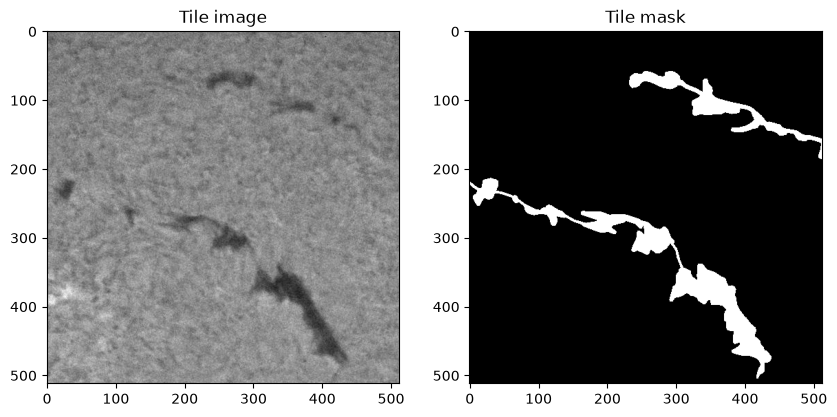

In [20]:
best_idx, best_count = None, 0
for i in range(min(2000, len(train_dataset))):  # cap search for speed
    img_t, mask_t = train_dataset[i]
    count = (mask_t > 0).sum().item()
    if count > best_count:
        best_count = count
        best_idx = i

print(f"Best tile: index {best_idx}, mask pixel count {best_count}")
img_t, mask_t = train_dataset[best_idx]

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(img_t.squeeze(), cmap='gray')
axes[0].set_title("Tile image")
axes[1].imshow(mask_t.squeeze(), cmap='gray')
axes[1].set_title("Tile mask")
plt.show()

In [21]:
from torch.utils.data import DataLoader

BATCH_SIZE = 4  # 4 GB VRAM: keep small for 512px tiles

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0, pin_memory=torch.cuda.is_available())
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=torch.cuda.is_available())

print("Train batches:", len(train_loader))
print("Val batches:", len(val_loader))

Train batches: 3634
Val batches: 1007


In [22]:
import segmentation_models_pytorch as smp
import torch.nn as nn

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Using:", device)

model = smp.Unet(
    encoder_name='resnet34',
    encoder_weights='imagenet',
    in_channels=1,       # grayscale
    classes=1,           # binary: filament vs background
    activation=None      # raw logits — we'll apply sigmoid in the loss
).to(device)

Using: cuda


In [23]:
class DiceBCELoss(nn.Module):
    def __init__(self):
        super().__init__()
        self.bce = nn.BCEWithLogitsLoss()

    def forward(self, logits, targets):
        bce_loss = self.bce(logits, targets)

        probs = torch.sigmoid(logits)
        smooth = 1.0
        intersection = (probs * targets).sum(dim=(1,2,3))
        dice = (2. * intersection + smooth) / (probs.sum(dim=(1,2,3)) + targets.sum(dim=(1,2,3)) + smooth)
        dice_loss = 1 - dice.mean()

        return bce_loss + dice_loss

criterion = DiceBCELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

In [24]:
from tqdm.auto import tqdm

EPOCHS = 15
os.makedirs(f'{PROJECT_ROOT}/checkpoints', exist_ok=True)
best_val_loss = float('inf')
checkpoint_path = f'{PROJECT_ROOT}/checkpoints/unet_resnet34_baseline.pt'

for epoch in range(EPOCHS):
    model.train()
    train_loss = 0.0
    train_bar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{EPOCHS} [train]")
    for imgs, masks in train_bar:
        imgs, masks = imgs.to(device), masks.to(device)

        optimizer.zero_grad()
        logits = model(imgs)
        loss = criterion(logits, masks)
        loss.backward()
        optimizer.step()

        train_loss += loss.item() * imgs.size(0)
        train_bar.set_postfix(loss=loss.item())

    train_loss /= len(train_dataset)

    model.eval()
    val_loss = 0.0
    val_bar = tqdm(val_loader, desc=f"Epoch {epoch+1}/{EPOCHS} [val]")
    with torch.no_grad():
        for imgs, masks in val_bar:
            imgs, masks = imgs.to(device), masks.to(device)
            logits = model(imgs)
            loss = criterion(logits, masks)
            val_loss += loss.item() * imgs.size(0)
            val_bar.set_postfix(loss=loss.item())
    val_loss /= len(val_dataset)

    print(f"Epoch {epoch+1}/{EPOCHS} — train_loss: {train_loss:.4f}, val_loss: {val_loss:.4f}")

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model.state_dict(), checkpoint_path)
        print(f"  ↳ saved new best checkpoint (val_loss={val_loss:.4f})")

Epoch 1/15 [train]:   0%|          | 0/3634 [00:00<?, ?it/s]

Epoch 1/15 [val]:   0%|          | 0/1007 [00:00<?, ?it/s]

Epoch 1/15 — train_loss: 0.7646, val_loss: 0.4914
  ↳ saved new best checkpoint (val_loss=0.4914)


Epoch 2/15 [train]:   0%|          | 0/3634 [00:00<?, ?it/s]

Epoch 2/15 [val]:   0%|          | 0/1007 [00:00<?, ?it/s]

Epoch 2/15 — train_loss: 0.4996, val_loss: 0.3116
  ↳ saved new best checkpoint (val_loss=0.3116)


... (35 outputs left out)

Epoch 14/15 — train_loss: 0.3801, val_loss: 0.2570
  ↳ saved new best checkpoint (val_loss=0.2570)


Epoch 15/15 [train]:   0%|          | 0/3634 [00:00<?, ?it/s]

Epoch 15/15 [val]:   0%|          | 0/1007 [00:00<?, ?it/s]

Epoch 15/15 — train_loss: 0.4135, val_loss: 0.3013


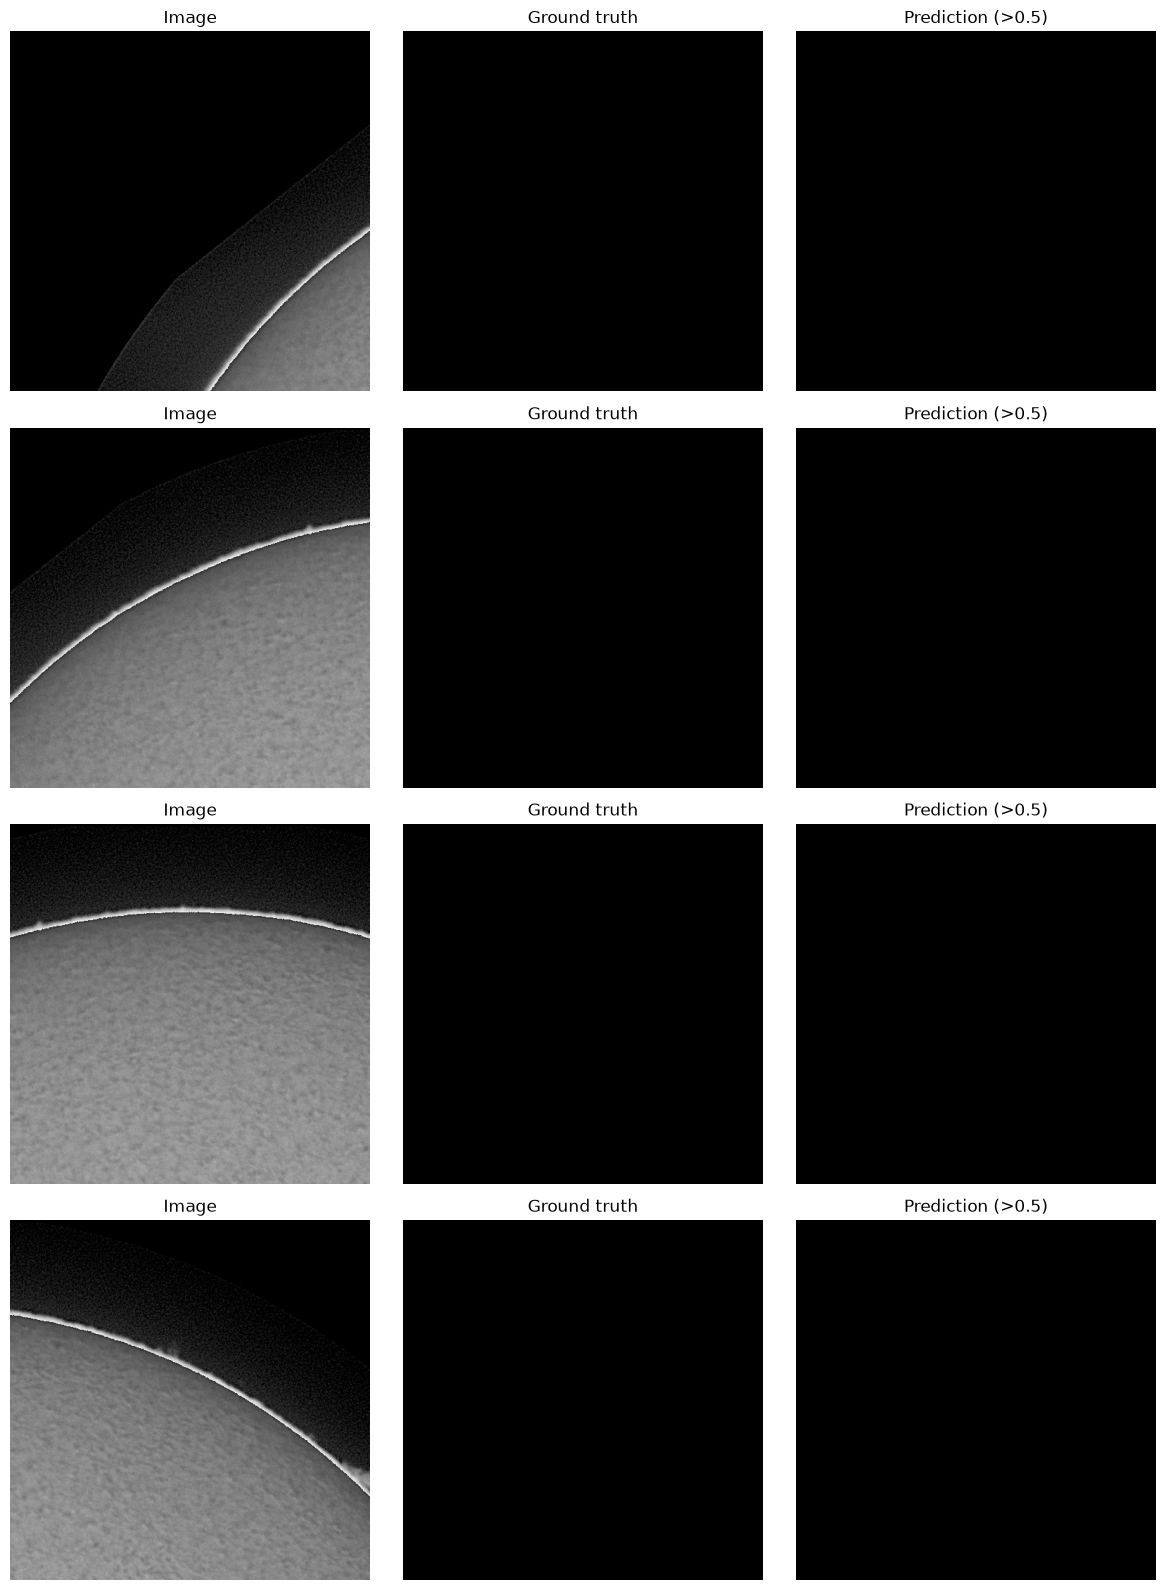

In [25]:
model.eval()

# grab a batch from val_loader
imgs, masks = next(iter(val_loader))
imgs, masks = imgs.to(device), masks.to(device)

with torch.no_grad():
    logits = model(imgs)
    preds = torch.sigmoid(logits)

imgs, masks, preds = imgs.cpu(), masks.cpu(), preds.cpu()

n = 4
fig, axes = plt.subplots(n, 3, figsize=(12, 4*n))
for i in range(n):
    axes[i,0].imshow(imgs[i].squeeze(), cmap='gray')
    axes[i,0].set_title("Image")
    axes[i,1].imshow(masks[i].squeeze(), cmap='gray')
    axes[i,1].set_title("Ground truth")
    axes[i,2].imshow(preds[i].squeeze() > 0.5, cmap='gray')
    axes[i,2].set_title("Prediction (>0.5)")
    for ax in axes[i]:
        ax.axis('off')
plt.tight_layout()
plt.show()

Found 6 non-empty val tiles (checked 15 total)


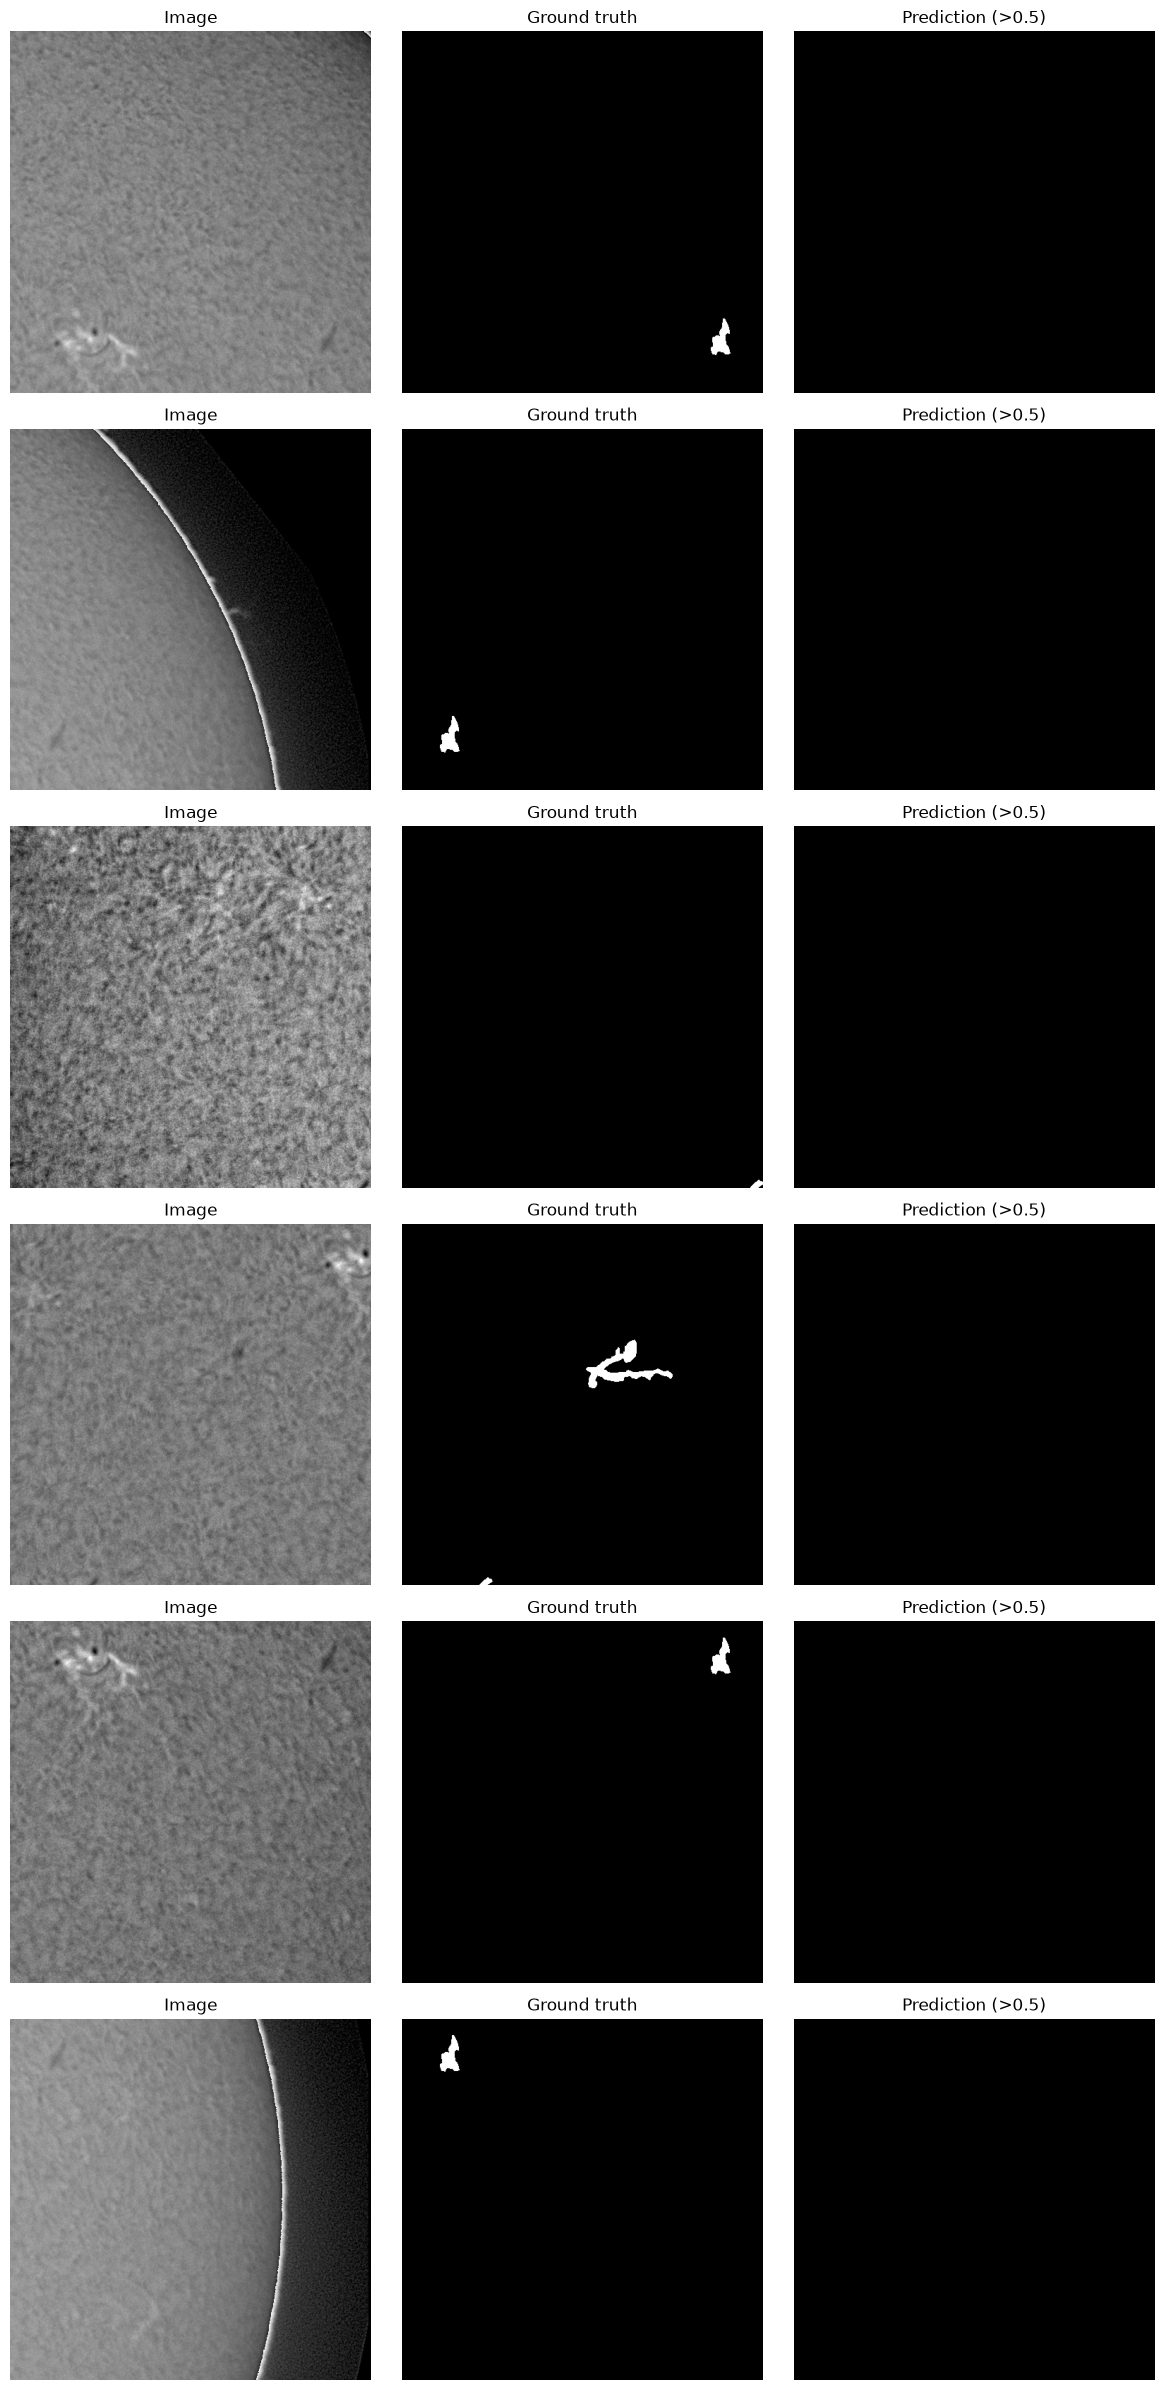

In [26]:
model.eval()

# scan val_dataset for tiles that actually contain filament pixels
nonempty_indices = []
for i in range(len(val_dataset)):
    _, mask_t = val_dataset[i]
    if mask_t.sum() > 0:
        nonempty_indices.append(i)
    if len(nonempty_indices) >= 6:
        break

print(f"Found {len(nonempty_indices)} non-empty val tiles (checked {i+1} total)")

# build a batch manually from these indices
imgs = torch.stack([val_dataset[idx][0] for idx in nonempty_indices])
masks = torch.stack([val_dataset[idx][1] for idx in nonempty_indices])
imgs_gpu, masks_gpu = imgs.to(device), masks.to(device)

with torch.no_grad():
    logits = model(imgs_gpu)
    preds = torch.sigmoid(logits).cpu()

n = len(nonempty_indices)
fig, axes = plt.subplots(n, 3, figsize=(12, 4*n))
for i in range(n):
    axes[i,0].imshow(imgs[i].squeeze(), cmap='gray')
    axes[i,0].set_title("Image")
    axes[i,1].imshow(masks[i].squeeze(), cmap='gray')
    axes[i,1].set_title("Ground truth")
    axes[i,2].imshow(preds[i].squeeze() > 0.5, cmap='gray')
    axes[i,2].set_title("Prediction (>0.5)")
    for ax in axes[i]:
        ax.axis('off')
plt.tight_layout()
plt.show()

Computing val IoU:   0%|          | 0/1007 [00:00<?, ?it/s]

Tiles with filament content: 1781
Mean pixel IoU (non-empty tiles): 0.2990
Median: 0.3041


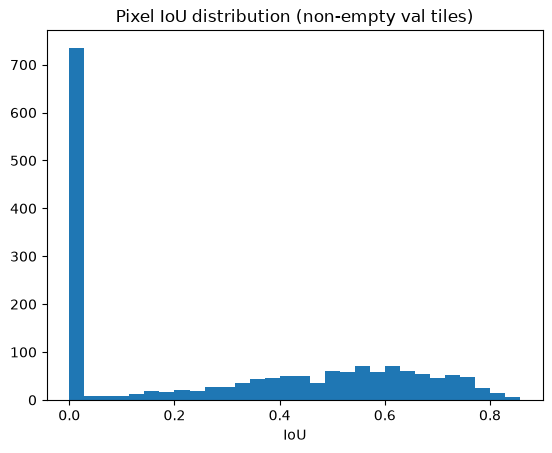

In [27]:
def compute_iou(pred_mask, gt_mask, threshold=0.5):
    pred_bin = (pred_mask > threshold).float()
    intersection = (pred_bin * gt_mask).sum()
    union = pred_bin.sum() + gt_mask.sum() - intersection
    if union == 0:
        return None  # both empty — skip, not a meaningful IoU
    return (intersection / union).item()

model.eval()
ious = []

with torch.no_grad():
    for imgs, masks in tqdm(val_loader, desc="Computing val IoU"):
        imgs, masks = imgs.to(device), masks.to(device)
        logits = model(imgs)
        preds = torch.sigmoid(logits)

        for i in range(imgs.size(0)):
            iou = compute_iou(preds[i].cpu(), masks[i].cpu())
            if iou is not None:
                ious.append(iou)

print(f"Tiles with filament content: {len(ious)}")
print(f"Mean pixel IoU (non-empty tiles): {np.mean(ious):.4f}")
print(f"Median: {np.median(ious):.4f}")

plt.hist(ious, bins=30)
plt.title("Pixel IoU distribution (non-empty val tiles)")
plt.xlabel("IoU")
plt.show()

Analyzing IoU vs GT size:   0%|          | 0/1007 [00:00<?, ?it/s]

Zero-IoU tiles: 584 / 1631
  Median GT size (zero-IoU tiles): 713.0 px
  Median GT size (non-zero tiles): 2354.0 px


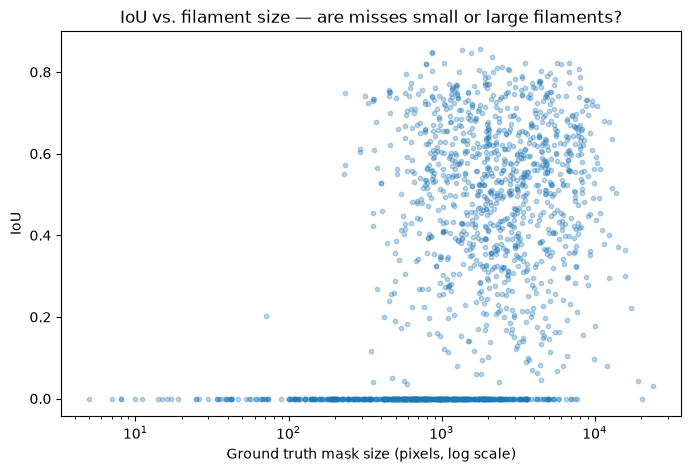

In [28]:
# correlate ground-truth mask size with IoU, specifically for the zero-IoU bucket
gt_sizes = []
iou_list = []

model.eval()
with torch.no_grad():
    for imgs, masks in tqdm(val_loader, desc="Analyzing IoU vs GT size"):
        imgs, masks = imgs.to(device), masks.to(device)
        logits = model(imgs)
        preds = torch.sigmoid(logits)

        for i in range(imgs.size(0)):
            gt_pixels = masks[i].sum().item()
            if gt_pixels == 0:
                continue
            iou = compute_iou(preds[i].cpu(), masks[i].cpu())
            gt_sizes.append(gt_pixels)
            iou_list.append(iou)

gt_sizes = np.array(gt_sizes)
iou_list = np.array(iou_list)

zero_mask = iou_list == 0
print(f"Zero-IoU tiles: {zero_mask.sum()} / {len(iou_list)}")
print(f"  Median GT size (zero-IoU tiles): {np.median(gt_sizes[zero_mask]):.1f} px")
print(f"  Median GT size (non-zero tiles): {np.median(gt_sizes[~zero_mask]):.1f} px")

plt.figure(figsize=(8,5))
plt.scatter(gt_sizes, iou_list, alpha=0.3, s=10)
plt.xscale('log')
plt.xlabel("Ground truth mask size (pixels, log scale)")
plt.ylabel("IoU")
plt.title("IoU vs. filament size — are misses small or large filaments?")
plt.show()

In [29]:
print("Model training mode:", model.training)  # should print False

Model training mode: False


In [30]:
checkpoint_path = f'{PROJECT_ROOT}/checkpoints/unet_resnet34_baseline.pt'
import os
print("Checkpoint exists:", os.path.exists(checkpoint_path))
print("Checkpoint size (MB):", os.path.getsize(checkpoint_path) / 1e6)

state_dict = torch.load(checkpoint_path, map_location=device)
missing, unexpected = model.load_state_dict(state_dict, strict=True)
print("Missing keys:", missing)
print("Unexpected keys:", unexpected)

Checkpoint exists: True
Checkpoint size (MB): 97.898615
Missing keys: []
Unexpected keys: []


In [31]:
print("Batch size:", val_loader.batch_size)  # should be 8, per original setup

Batch size: 4


In [32]:
val_loader = DataLoader(val_dataset, batch_size=8, shuffle=False, num_workers=0, pin_memory=True)
print("Batch size:", val_loader.batch_size)  # confirm it's 8 now

Batch size: 8


In [33]:
print("Model training mode:", model.training)  # should be False
if model.training:
    model.eval()

Model training mode: False


In [34]:
gt_sizes = []
iou_list = []

model.eval()
with torch.no_grad():
    for imgs, masks in tqdm(val_loader, desc="Analyzing IoU vs GT size"):
        imgs, masks = imgs.to(device), masks.to(device)
        logits = model(imgs)
        preds = torch.sigmoid(logits)

        for i in range(imgs.size(0)):
            gt_pixels = masks[i].sum().item()
            if gt_pixels == 0:
                continue
            iou = compute_iou(preds[i].cpu(), masks[i].cpu())
            gt_sizes.append(gt_pixels)
            iou_list.append(iou)

gt_sizes = np.array(gt_sizes)
iou_list = np.array(iou_list)

zero_mask = iou_list == 0
print(f"Zero-IoU tiles: {zero_mask.sum()} / {len(iou_list)}")
print(f"  Median GT size (zero-IoU tiles): {np.median(gt_sizes[zero_mask]):.1f} px")
print(f"  Median GT size (non-zero tiles): {np.median(gt_sizes[~zero_mask]):.1f} px")

Analyzing IoU vs GT size:   0%|          | 0/504 [00:00<?, ?it/s]

Zero-IoU tiles: 392 / 1631
  Median GT size (zero-IoU tiles): 564.0 px
  Median GT size (non-zero tiles): 2113.0 px


Found 7 large zero-IoU examples


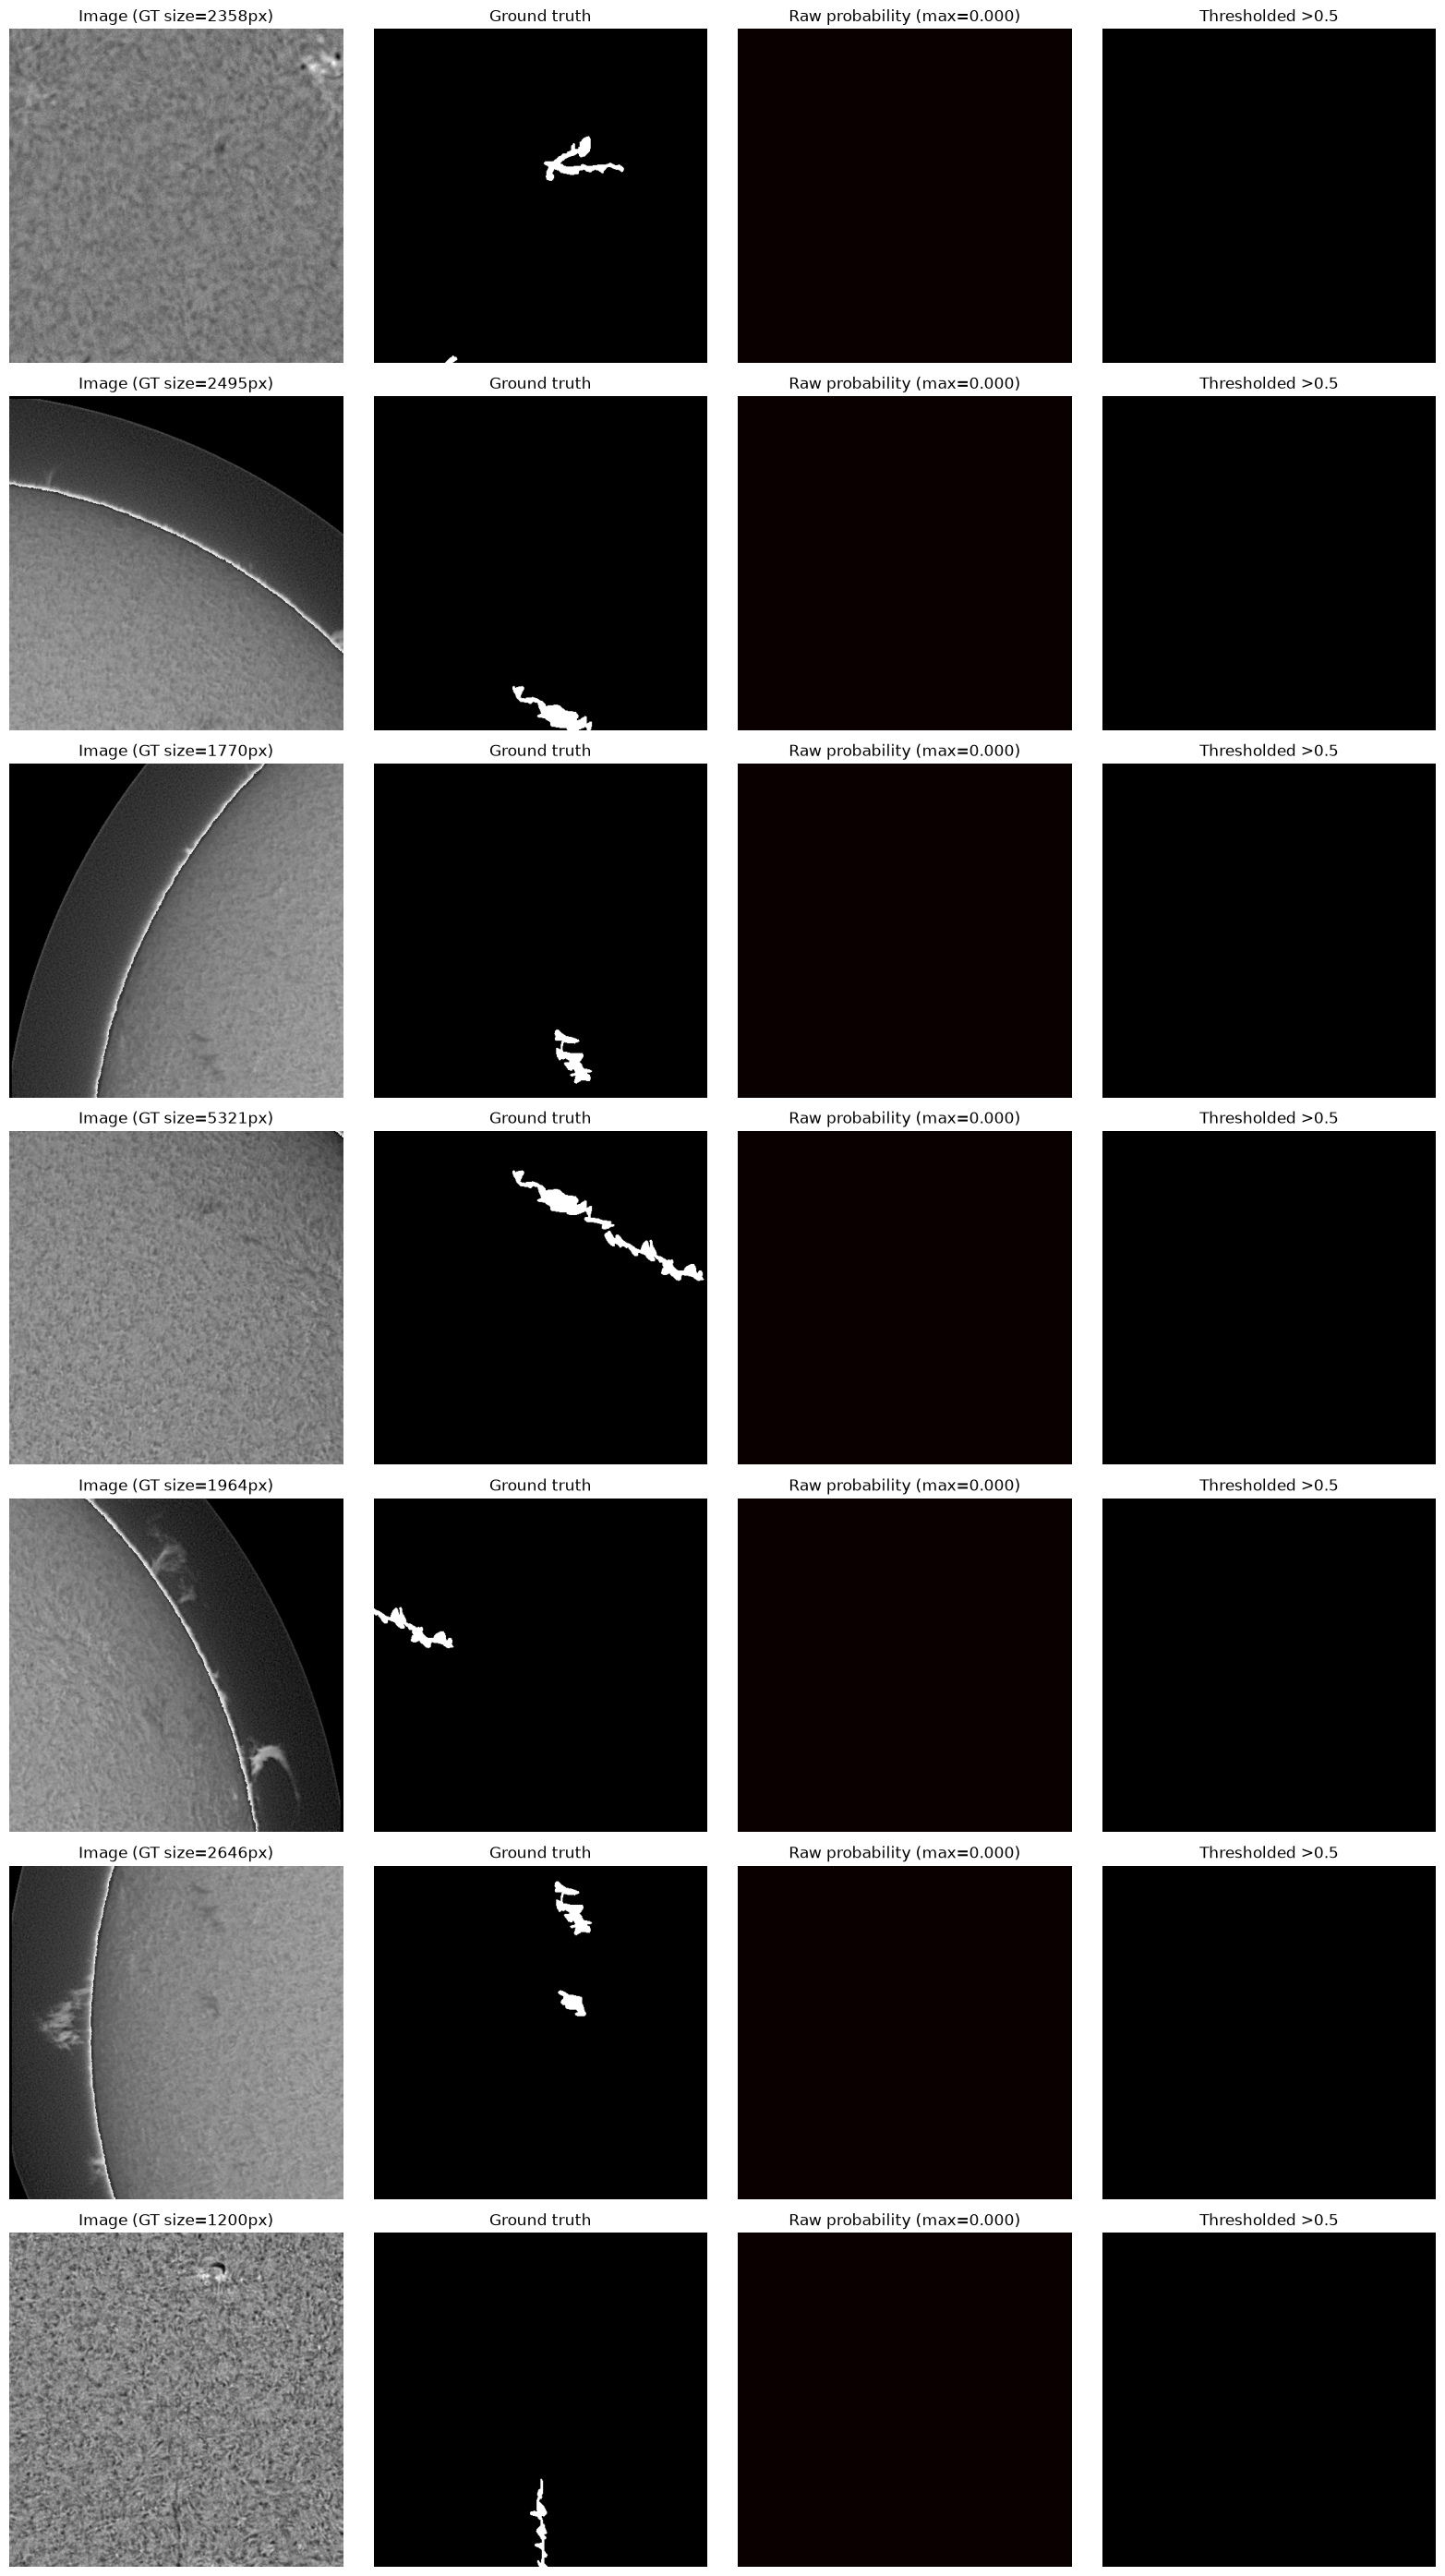

In [35]:
model.eval()
large_miss_samples = []

with torch.no_grad():
    for batch_idx, (imgs, masks) in enumerate(val_loader):
        imgs_gpu, masks_gpu = imgs.to(device), masks.to(device)
        logits = model(imgs_gpu)
        preds = torch.sigmoid(logits).cpu()

        for i in range(imgs.size(0)):
            gt_size = masks[i].sum().item()
            iou = compute_iou(preds[i], masks[i])
            if iou == 0 and gt_size > 1000:
                large_miss_samples.append((imgs[i], masks[i], preds[i], gt_size))

        if len(large_miss_samples) >= 6:
            break

print(f"Found {len(large_miss_samples)} large zero-IoU examples")

n = len(large_miss_samples)
fig, axes = plt.subplots(n, 4, figsize=(16, 4*n))
for i, (img, mask, pred, gt_size) in enumerate(large_miss_samples):
    axes[i,0].imshow(img.squeeze(), cmap='gray')
    axes[i,0].set_title(f"Image (GT size={int(gt_size)}px)")
    axes[i,1].imshow(mask.squeeze(), cmap='gray')
    axes[i,1].set_title("Ground truth")
    axes[i,2].imshow(pred.squeeze(), cmap='hot', vmin=0, vmax=1)
    axes[i,2].set_title(f"Raw probability (max={pred.max().item():.3f})")
    axes[i,3].imshow(pred.squeeze() > 0.5, cmap='gray')
    axes[i,3].set_title("Thresholded >0.5")
    for ax in axes[i]:
        ax.axis('off')
plt.tight_layout()
plt.show()

In [36]:
model.eval()
with torch.no_grad():
    for img, mask, pred, gt_size in large_miss_samples[:3]:
        img_gpu = img.unsqueeze(0).to(device)
        logits = model(img_gpu)
        print(f"GT size={int(gt_size)}px — logit min: {logits.min().item():.3f}, "
              f"max: {logits.max().item():.3f}, mean: {logits.mean().item():.3f}")

GT size=2358px — logit min: -25.361, max: -12.045, mean: -20.193
GT size=2495px — logit min: -47.268, max: -12.051, mean: -24.345
GT size=1770px — logit min: -49.580, max: -12.300, mean: -24.465


In [37]:
model.eval()
hit_stats, miss_stats = [], []

with torch.no_grad():
    for imgs, masks in val_loader:
        imgs_gpu, masks_gpu = imgs.to(device), masks.to(device)
        logits = model(imgs_gpu)
        preds = torch.sigmoid(logits).cpu()

        for i in range(imgs.size(0)):
            gt_size = masks[i].sum().item()
            if gt_size == 0:
                continue
            iou = compute_iou(preds[i], masks[i])
            img_np = imgs[i].squeeze().numpy()
            stats = (img_np.mean(), img_np.std())
            (miss_stats if iou == 0 else hit_stats).append(stats)

hit_means = [s[0] for s in hit_stats]; hit_stds = [s[1] for s in hit_stats]
miss_means = [s[0] for s in miss_stats]; miss_stds = [s[1] for s in miss_stats]

print(f"Hits  — mean brightness: {np.mean(hit_means):.3f}, mean contrast(std): {np.mean(hit_stds):.3f}")
print(f"Misses— mean brightness: {np.mean(miss_means):.3f}, mean contrast(std): {np.mean(miss_stds):.3f}")

Hits  — mean brightness: 0.451, mean contrast(std): 0.095
Misses— mean brightness: 0.391, mean contrast(std): 0.122


In [38]:
import scipy.ndimage as ndi

def mask_elongation(mask_np):
    labeled, n = ndi.label(mask_np)
    if n == 0:
        return None
    sizes = ndi.sum(mask_np, labeled, range(1, n+1))
    biggest = np.argmax(sizes) + 1
    coords = np.argwhere(labeled == biggest)
    if len(coords) < 2:
        return None
    cov = np.cov(coords.T)
    eigvals = np.linalg.eigvalsh(cov)
    return np.sqrt(eigvals[-1] / max(eigvals[0], 1e-6))  # major/minor axis ratio

hit_elong, miss_elong = [], []
model.eval()
with torch.no_grad():
    for imgs, masks in val_loader:
        imgs_gpu = imgs.to(device)
        preds = torch.sigmoid(model(imgs_gpu)).cpu()
        for i in range(imgs.size(0)):
            mask_np = masks[i].squeeze().numpy()
            if mask_np.sum() == 0:
                continue
            iou = compute_iou(preds[i], masks[i])
            e = mask_elongation(mask_np)
            if e is not None:
                (miss_elong if iou == 0 else hit_elong).append(e)

print(f"Hits  — mean elongation ratio: {np.mean(hit_elong):.2f}")
print(f"Misses— mean elongation ratio: {np.mean(miss_elong):.2f}")

Hits  — mean elongation ratio: 5.01
Misses— mean elongation ratio: 3.93


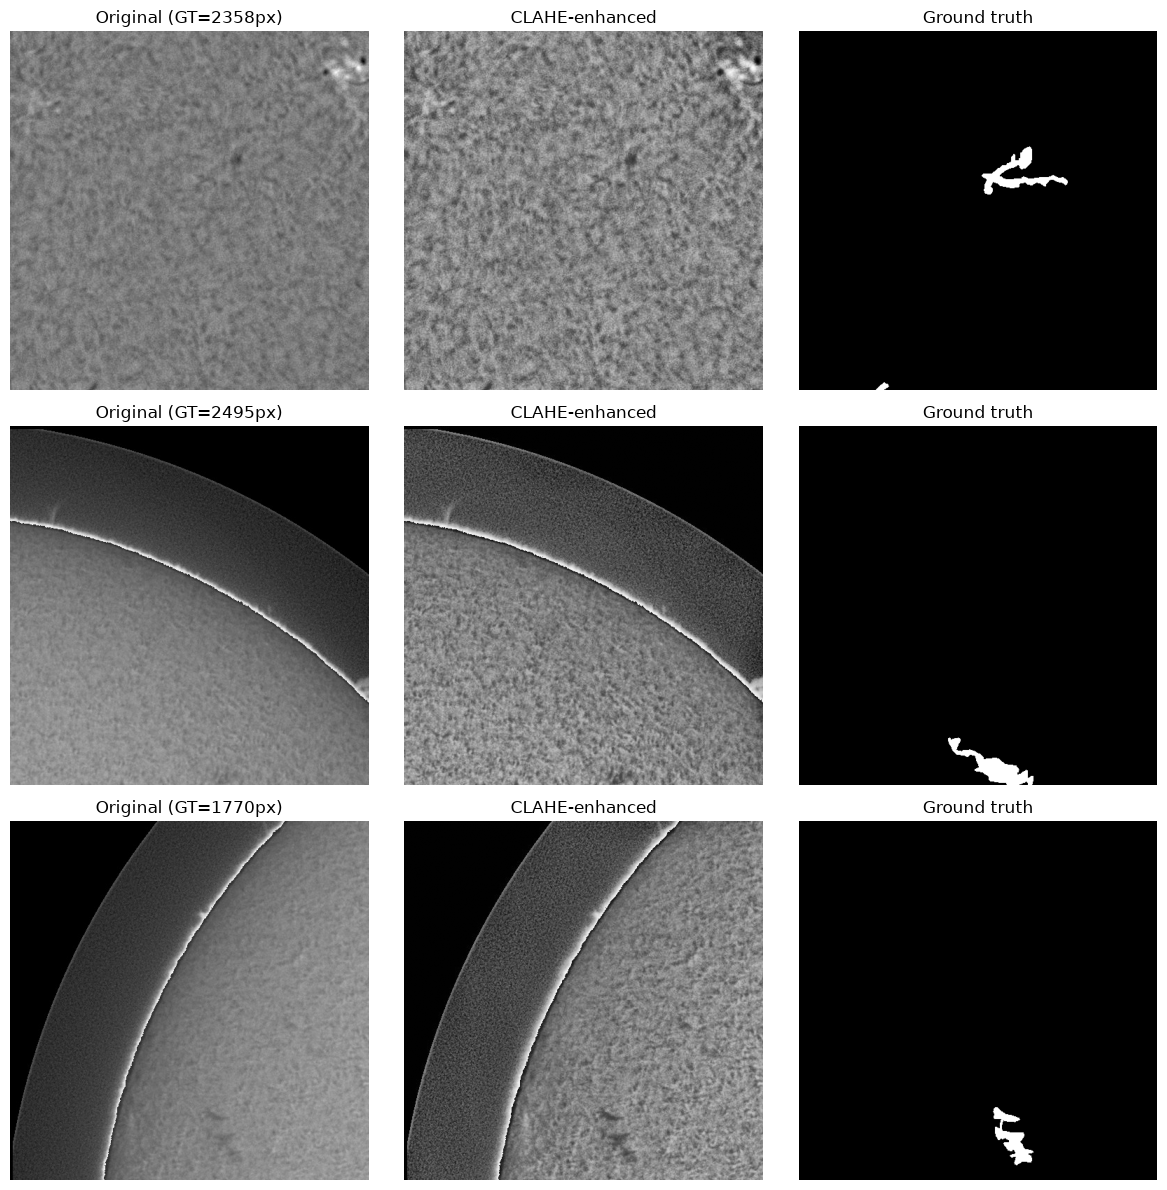

In [39]:
import cv2

fig, axes = plt.subplots(3, 3, figsize=(12, 12))
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8,8))

for row, (img, mask, pred, gt_size) in enumerate(large_miss_samples[:3]):
    img_np = (img.squeeze().numpy() * 255).astype(np.uint8)
    img_clahe = clahe.apply(img_np)

    axes[row,0].imshow(img_np, cmap='gray')
    axes[row,0].set_title(f"Original (GT={int(gt_size)}px)")
    axes[row,1].imshow(img_clahe, cmap='gray')
    axes[row,1].set_title("CLAHE-enhanced")
    axes[row,2].imshow(mask.squeeze(), cmap='gray')
    axes[row,2].set_title("Ground truth")
    for ax in axes[row]:
        ax.axis('off')
plt.tight_layout()
plt.show()

In [40]:
class TverskyLoss(nn.Module):
    def __init__(self, alpha=0.3, beta=0.7, smooth=1.0):
        """
        alpha: weight on false positives
        beta:  weight on false negatives (higher = punish misses harder)
        """
        super().__init__()
        self.alpha = alpha
        self.beta = beta
        self.smooth = smooth

    def forward(self, logits, targets):
        probs = torch.sigmoid(logits)
        TP = (probs * targets).sum(dim=(1,2,3))
        FP = (probs * (1 - targets)).sum(dim=(1,2,3))
        FN = ((1 - probs) * targets).sum(dim=(1,2,3))

        tversky = (TP + self.smooth) / (TP + self.alpha*FP + self.beta*FN + self.smooth)
        return 1 - tversky.mean()

criterion = TverskyLoss(alpha=0.3, beta=0.7)

In [43]:
import torch
from torch.utils.data import Dataset
from pycocotools import mask as maskUtils
import cv2

class FilamentTileDataset(Dataset):
    def __init__(self, image_ids, coco_data, images_by_id, anns_by_image_id,
                 image_dir, tile_size=512, stride=384, skip_empty_prob=0.5):
        self.image_dir = image_dir
        self.tile_size = tile_size
        self.images_by_id = images_by_id
        self.anns_by_image_id = anns_by_image_id
        self.samples = []

        self.clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8,8))

        rng = np.random.RandomState(42)

        for image_id in image_ids:
            img_info = images_by_id[image_id]
            w, h = img_info['width'], img_info['height']
            anns = anns_by_image_id.get(image_id, [])

            for (x0, y0) in generate_tile_coords(w, h, tile_size, stride):
                tile_box_poly = box(x0, y0, x0 + tile_size, y0 + tile_size)
                has_filament = False
                for ann in anns:
                    seg = ann['segmentation'][0]
                    coords = list(zip(seg[0::2], seg[1::2]))
                    p = Polygon(coords)
                    if not p.is_valid:
                        p = p.buffer(0)
                    if p.intersects(tile_box_poly):
                        has_filament = True
                        break

                if not has_filament and rng.rand() < skip_empty_prob:
                    continue

                self.samples.append((image_id, x0, y0))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        image_id, x0, y0 = self.samples[idx]
        img_info = self.images_by_id[image_id]
        anns = self.anns_by_image_id.get(image_id, [])

        img_path = f"{self.image_dir}/{img_info['file_name']}"
        full_img = np.array(Image.open(img_path).convert('L'))
        tile_img = full_img[y0:y0+self.tile_size, x0:x0+self.tile_size]

        # CLAHE contrast enhancement
        tile_img = self.clahe.apply(tile_img.astype(np.uint8))

        mask = np.zeros((self.tile_size, self.tile_size), dtype=np.uint8)
        for ann in anns:
            seg = ann['segmentation'][0]
            clipped_polys = clip_annotation_to_tile(seg, x0, y0, self.tile_size)
            for local_coords in clipped_polys:
                flat = [c for point in local_coords for c in point]
                rles = maskUtils.frPyObjects([flat], self.tile_size, self.tile_size)
                rle = maskUtils.merge(rles)
                inst_mask = maskUtils.decode(rle)
                mask[inst_mask > 0] = 255

        img_tensor = torch.from_numpy(tile_img).float().unsqueeze(0) / 255.0
        mask_tensor = torch.from_numpy(mask).float().unsqueeze(0) / 255.0

        return img_tensor, mask_tensor

In [44]:
train_dataset = FilamentTileDataset(
    image_ids=train_image_ids, coco_data=coco_data,
    images_by_id=images_by_id, anns_by_image_id=anns_by_image_id,
    image_dir=f"{DATA_ROOT}/train/train_images",
    tile_size=512, stride=384, skip_empty_prob=0.5
)

val_dataset = FilamentTileDataset(
    image_ids=val_image_ids, coco_data=coco_data,
    images_by_id=images_by_id, anns_by_image_id=anns_by_image_id,
    image_dir=f"{DATA_ROOT}/train/train_images",
    tile_size=512, stride=384, skip_empty_prob=0.0
)

train_loader = DataLoader(train_dataset, batch_size=8, shuffle=True, num_workers=0, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=8, shuffle=False, num_workers=0, pin_memory=True)

print("Train tiles:", len(train_dataset))
print("Val tiles:", len(val_dataset))

Train tiles: 17442
Val tiles: 4025


In [45]:
model = smp.Unet(
    encoder_name='resnet34',
    encoder_weights='imagenet',
    in_channels=1,
    classes=1,
    activation=None
).to(device)

class TverskyLoss(nn.Module):
    def __init__(self, alpha=0.3, beta=0.7, smooth=1.0):
        super().__init__()
        self.alpha = alpha
        self.beta = beta
        self.smooth = smooth

    def forward(self, logits, targets):
        probs = torch.sigmoid(logits)
        TP = (probs * targets).sum(dim=(1,2,3))
        FP = (probs * (1 - targets)).sum(dim=(1,2,3))
        FN = ((1 - probs) * targets).sum(dim=(1,2,3))
        tversky = (TP + self.smooth) / (TP + self.alpha*FP + self.beta*FN + self.smooth)
        return 1 - tversky.mean()

criterion = TverskyLoss(alpha=0.3, beta=0.7)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

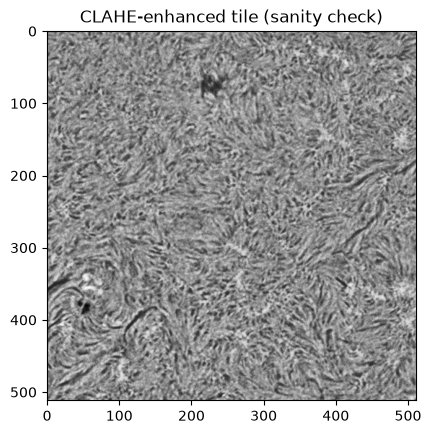

In [46]:
img_t, mask_t = train_dataset[10]
plt.imshow(img_t.squeeze(), cmap='gray')
plt.title("CLAHE-enhanced tile (sanity check)")
plt.show()

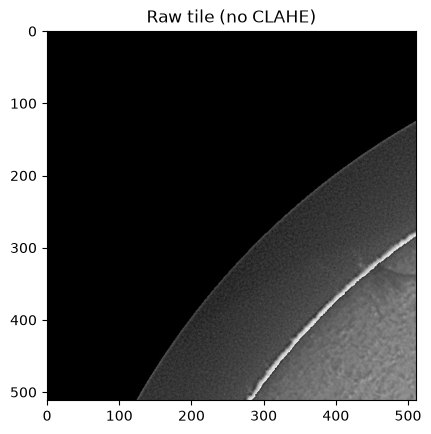

In [48]:
img_info = images_by_id[train_image_ids[0]]
full_img = np.array(Image.open(f"{DATA_ROOT}/train/train_images/{img_info['file_name']}").convert('L'))
test_tile = full_img[0:512, 0:512]

plt.imshow(test_tile, cmap='gray')
plt.title("Raw tile (no CLAHE)")
plt.show()

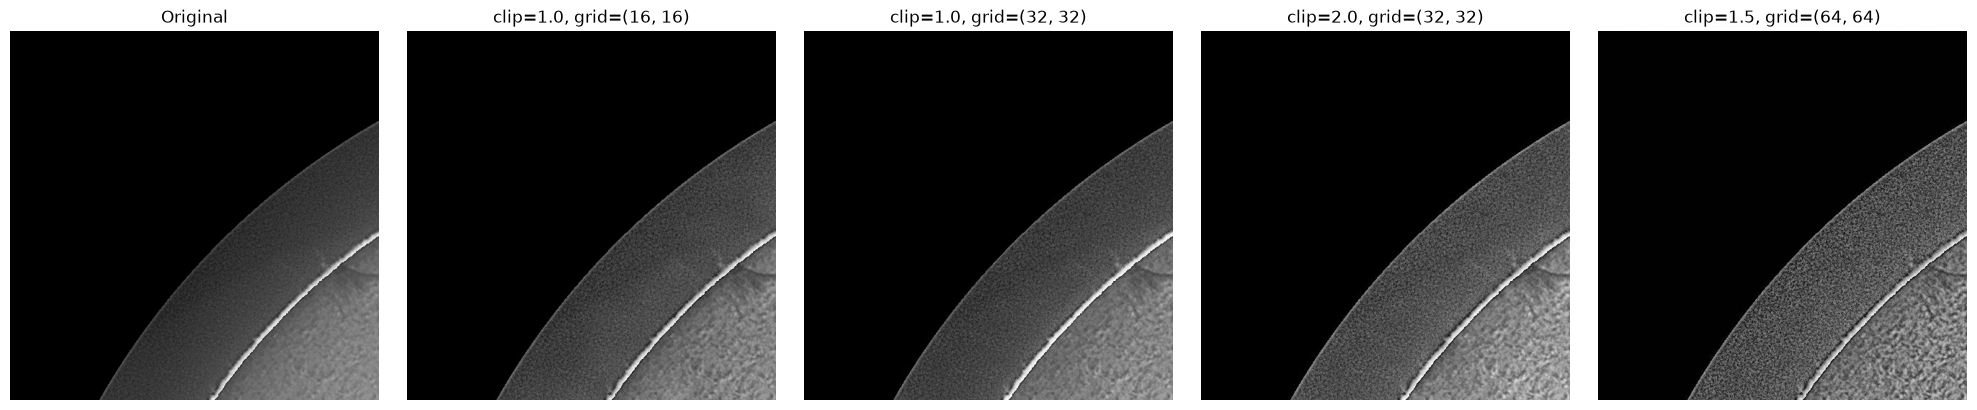

In [49]:
configs = [
    (1.0, (16,16)),
    (1.0, (32,32)),
    (2.0, (32,32)),
    (1.5, (64,64)),
]

fig, axes = plt.subplots(1, len(configs)+1, figsize=(20,4))
axes[0].imshow(test_tile, cmap='gray')
axes[0].set_title("Original")
axes[0].axis('off')

for i, (clip, grid) in enumerate(configs):
    c = cv2.createCLAHE(clipLimit=clip, tileGridSize=grid)
    enhanced = c.apply(test_tile.astype(np.uint8))
    axes[i+1].imshow(enhanced, cmap='gray')
    axes[i+1].set_title(f"clip={clip}, grid={grid}")
    axes[i+1].axis('off')
plt.tight_layout()
plt.show()

In [60]:
import torch
from torch.utils.data import Dataset
from pycocotools import mask as maskUtils
import cv2

class FilamentTileDataset(Dataset):
    def __init__(self, image_ids, coco_data, images_by_id, anns_by_image_id,
                 image_dir, tile_size=512, stride=384, skip_empty_prob=0.5):
        self.image_dir = image_dir
        self.tile_size = tile_size
        self.images_by_id = images_by_id
        self.anns_by_image_id = anns_by_image_id
        self.samples = []

        self.clahe = cv2.createCLAHE(clipLimit=1.0, tileGridSize=(16,16))

        rng = np.random.RandomState(42)

        for image_id in image_ids:
            img_info = images_by_id[image_id]
            w, h = img_info['width'], img_info['height']
            anns = anns_by_image_id.get(image_id, [])

            for (x0, y0) in generate_tile_coords(w, h, tile_size, stride):
                tile_box_poly = box(x0, y0, x0 + tile_size, y0 + tile_size)
                has_filament = False
                for ann in anns:
                    seg = ann['segmentation'][0]
                    coords = list(zip(seg[0::2], seg[1::2]))
                    p = Polygon(coords)
                    if not p.is_valid:
                        p = p.buffer(0)
                    if p.intersects(tile_box_poly):
                        has_filament = True
                        break

                if not has_filament and rng.rand() < skip_empty_prob:
                    continue

                self.samples.append((image_id, x0, y0))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        image_id, x0, y0 = self.samples[idx]
        img_info = self.images_by_id[image_id]
        anns = self.anns_by_image_id.get(image_id, [])

        img_path = f"{self.image_dir}/{img_info['file_name']}"
        full_img = np.array(Image.open(img_path).convert('L'))
        tile_img = full_img[y0:y0+self.tile_size, x0:x0+self.tile_size]

        tile_img = self.clahe.apply(np.ascontiguousarray(tile_img, dtype=np.uint8))

        mask = np.zeros((self.tile_size, self.tile_size), dtype=np.uint8)
        for ann in anns:
            seg = ann['segmentation'][0]
            clipped_polys = clip_annotation_to_tile(seg, x0, y0, self.tile_size)
            for local_coords in clipped_polys:
                flat = [c for point in local_coords for c in point]
                rles = maskUtils.frPyObjects([flat], self.tile_size, self.tile_size)
                rle = maskUtils.merge(rles)
                inst_mask = maskUtils.decode(rle)
                mask[inst_mask > 0] = 255

        img_tensor = torch.from_numpy(tile_img).float().unsqueeze(0) / 255.0
        mask_tensor = torch.from_numpy(mask).float().unsqueeze(0) / 255.0

        return img_tensor, mask_tensor


In [61]:
train_dataset = FilamentTileDataset(
    image_ids=train_image_ids, coco_data=coco_data,
    images_by_id=images_by_id, anns_by_image_id=anns_by_image_id,
    image_dir=f"{DATA_ROOT}/train/train_images",
    tile_size=512, stride=384, skip_empty_prob=0.5
)

val_dataset = FilamentTileDataset(
    image_ids=val_image_ids, coco_data=coco_data,
    images_by_id=images_by_id, anns_by_image_id=anns_by_image_id,
    image_dir=f"{DATA_ROOT}/train/train_images",
    tile_size=512, stride=384, skip_empty_prob=0.0
)

train_loader = DataLoader(train_dataset, batch_size=8, shuffle=True, num_workers=0, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=8, shuffle=False, num_workers=0, pin_memory=True)

print("Train tiles:", len(train_dataset))
print("Val tiles:", len(val_dataset))

Train tiles: 17442
Val tiles: 4025


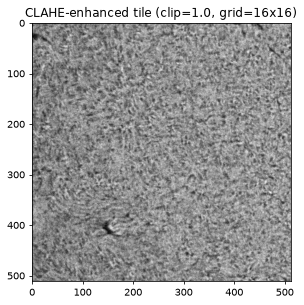

In [62]:
img_t, mask_t = train_dataset[10]
plt.imshow(img_t.squeeze(), cmap='gray')
plt.title("CLAHE-enhanced tile (clip=1.0, grid=16x16)")
plt.show()

## Final model: CLAHE + BCE + Tversky

The plain `TverskyLoss` defined above **collapses to predicting all-background**.
On an empty tile, predicting nothing drops the loss from ~1.0 to 0, while on a
filament tile it only costs ~0.02. With half the tiles empty, suppression wins:
after one epoch every logit sat near -10, no pixel anywhere exceeded 0.0003, and
mean IoU was exactly 0.0000 at every threshold. Once saturated it cannot recover,
because the gradient of any region-based loss carries a `p(1-p)` factor that
vanishes there.

Adding BCE back fixes it. Its gradient for a missed positive stays at `(p-1) ~ -1`
no matter how saturated the prediction, so the escape route stays open, while
Tversky still supplies the asymmetry we want (`beta > alpha` penalises false
negatives harder than false positives).

In [63]:
class BCETverskyLoss(nn.Module):
    def __init__(self, alpha=0.3, beta=0.7, smooth=1.0):
        super().__init__()
        self.alpha, self.beta, self.smooth = alpha, beta, smooth
        self.bce = nn.BCEWithLogitsLoss()

    def forward(self, logits, targets):
        # float32 regardless of autocast: these sums reach ~262k and would
        # overflow fp16 (max 65504) on a densely-positive tile.
        logits, targets = logits.float(), targets.float()
        bce_loss = self.bce(logits, targets)

        probs = torch.sigmoid(logits)
        dims = (1, 2, 3)
        tp = (probs * targets).sum(dim=dims)
        fp = (probs * (1 - targets)).sum(dim=dims)
        fn = ((1 - probs) * targets).sum(dim=dims)
        tversky = (tp + self.smooth) / (tp + self.alpha * fp + self.beta * fn + self.smooth)
        return bce_loss + (1 - tversky).mean()


criterion = BCETverskyLoss(alpha=0.3, beta=0.7)
print(criterion)

BCETverskyLoss(
  (bce): BCEWithLogitsLoss()
)


## Training

Trained for 15 epochs with this loss at batch size 4 and AMP (the RTX 2050 has
only ~1.5 GB free, and peak usage was 1.2 GiB). Roughly 27 min per epoch.

**Checkpoint selection is on validation IoU, not `val_loss`.** That matters here:
on two separate epochs the loss improved while IoU fell sharply, because ~60% of
validation tiles are empty and a model that predicts less scores a lower loss
while finding fewer filaments. Selecting on loss would have kept the worse model.

The run is in `src/filament.py` (`F.train`), which is the same code as a module so
it can be resumed. Weights load below rather than retraining.

In [64]:
import json

import segmentation_models_pytorch as smp

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
CKPT = f'{PROJECT_ROOT}/checkpoints/unet_resnet34_clahe_bce_tversky_best.pt'
HIST = f'{PROJECT_ROOT}/checkpoints/unet_resnet34_clahe_bce_tversky_history.json'

model = smp.Unet(encoder_name='resnet34', encoder_weights=None,
                 in_channels=1, classes=1, activation=None).to(device)
ckpt = torch.load(CKPT, map_location=device)
model.load_state_dict(ckpt['model'])
model.eval()

# The checkpoint only carries history up to the epoch it was saved at (11).
# The history file has all 15, including the drop after the peak.
with open(HIST) as f:
    hist = json.load(f)

print(f"loaded epoch {ckpt['epoch']}, best val IoU {ckpt['best_val_iou']:.4f}")
print(f"{'ep':>3} {'train':>7} {'val':>7} {'IoU':>7} {'miss%':>7}")
for h in hist:
    star = '  <-- selected' if h['epoch'] == ckpt['epoch'] else ''
    print(f"{h['epoch']:3d} {h['train_loss']:7.4f} {h['val_loss']:7.4f} "
          f"{h['val_iou']:7.4f} {100*h['miss_rate']:7.1f}{star}")

loaded epoch 11, best val IoU 0.4238
 ep   train     val     IoU   miss%
  2  0.4559  0.3072  0.3772    23.2
  3  0.4402  0.2797  0.3498    30.1
  4  0.4395  0.2932  0.3713    25.0
  5  0.4014  0.2599  0.3900    24.2
  6  0.3825  0.2720  0.3926    24.0
  7  0.3710  0.2557  0.3987    24.6
  8  0.3727  0.2578  0.4160    21.2
  9  0.3687  0.2994  0.2973    34.6
 10  0.3516  0.2686  0.3709    29.3
 11  0.3582  0.2741  0.4238    19.3  <-- selected
 12  0.3437  0.2645  0.4001    25.1
 13  0.3442  0.2522  0.4116    23.1
 14  0.3522  0.3188  0.2968    38.6
 15  0.3579  0.2691  0.3423    35.2


In [65]:
# Validation metrics for the selected checkpoint, on this notebook's val_dataset.
ious = []
with torch.no_grad():
    for imgs, masks in val_loader:
        imgs, masks = imgs.to(device), masks.to(device)
        with torch.amp.autocast('cuda'):
            logits = model(imgs)
        probs = torch.sigmoid(logits.float())
        for b in range(imgs.size(0)):
            if masks[b].sum() == 0:
                continue                      # empty tile: IoU undefined
            pred = (probs[b] > 0.5).float()
            inter = (pred * masks[b]).sum()
            union = pred.sum() + masks[b].sum() - inter
            if union > 0:
                ious.append((inter / union).item())

ious = np.array(ious)
print(f"val tiles containing filaments : {len(ious)}")
print(f"mean pixel IoU                 : {ious.mean():.4f}")
print(f"median IoU                     : {np.median(ious):.4f}")
print(f"complete misses (IoU = 0)      : {100*(ious == 0).mean():.1f}%")
print(f"tiles with IoU > 0.5           : {100*(ious > 0.5).mean():.1f}%")
print()
print("baseline (Dice+BCE, no CLAHE)  : IoU 0.39-0.48, misses 20-24%")

val tiles containing filaments : 1631
mean pixel IoU                 : 0.4238
median IoU                     : 0.4977
complete misses (IoU = 0)      : 19.3%
tiles with IoU > 0.5           : 49.5%

baseline (Dice+BCE, no CLAHE)  : IoU 0.39-0.48, misses 20-24%


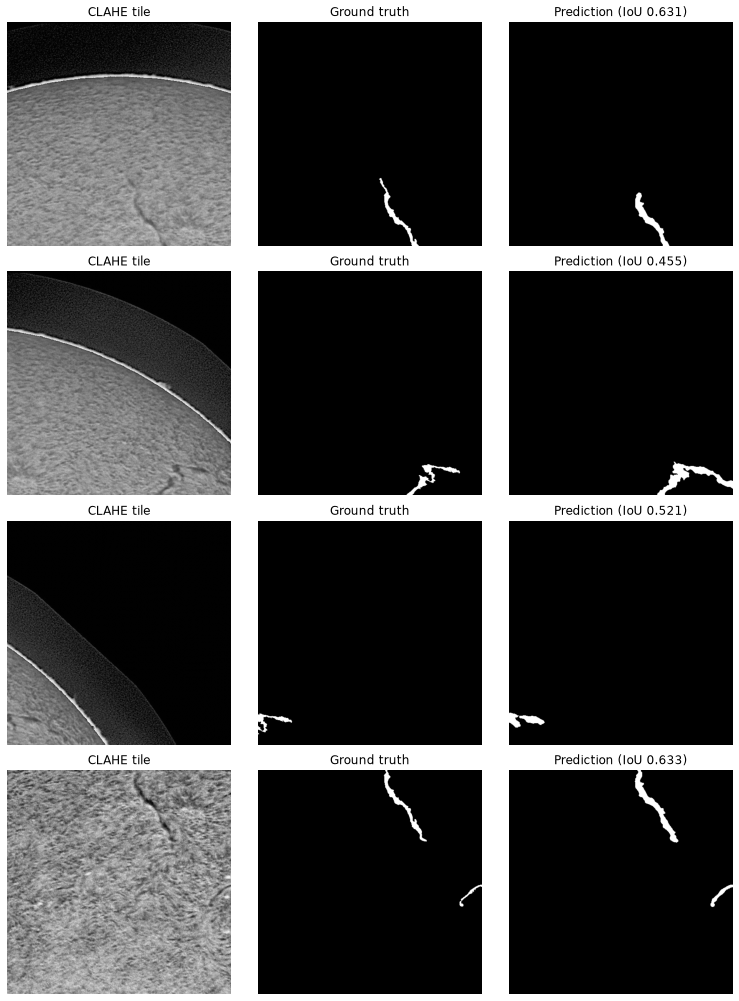

In [66]:
# Qualitative check: original tile, ground truth, prediction
nonempty = [i for i in range(400) if val_dataset[i][1].sum() > 0][:4]

fig, axes = plt.subplots(len(nonempty), 3, figsize=(11, 3.6 * len(nonempty)))
with torch.no_grad():
    for r, idx in enumerate(nonempty):
        img, gt = val_dataset[idx]
        with torch.amp.autocast('cuda'):
            logits = model(img.unsqueeze(0).to(device))
        pred = (torch.sigmoid(logits.float()).cpu()[0] > 0.5).float()

        inter = (pred * gt).sum()
        union = pred.sum() + gt.sum() - inter
        iou = (inter / union).item() if union > 0 else float('nan')

        axes[r, 0].imshow(img.squeeze(), cmap='gray')
        axes[r, 0].set_title('CLAHE tile')
        axes[r, 1].imshow(gt.squeeze(), cmap='gray')
        axes[r, 1].set_title('Ground truth')
        axes[r, 2].imshow(pred.squeeze(), cmap='gray')
        axes[r, 2].set_title(f'Prediction (IoU {iou:.3f})')
        for ax in axes[r]:
            ax.axis('off')
plt.tight_layout()
plt.show()

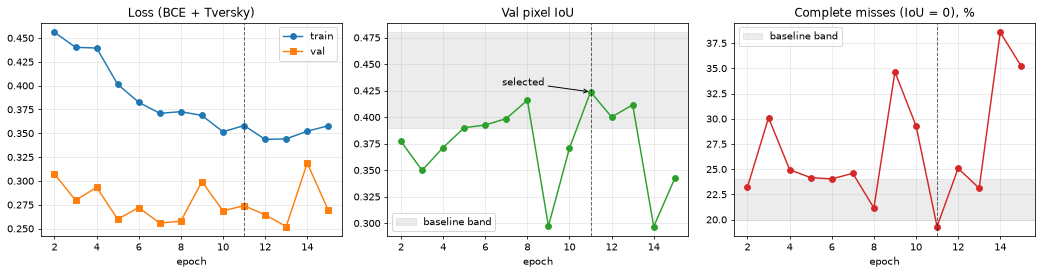

In [67]:
# Training curves over all 15 epochs
ep = [h['epoch'] for h in hist]
best_ep = ckpt['epoch']

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].plot(ep, [h['train_loss'] for h in hist], 'o-', label='train')
ax[0].plot(ep, [h['val_loss'] for h in hist], 's-', label='val')
ax[0].set_title('Loss (BCE + Tversky)'); ax[0].legend()
ax[1].plot(ep, [h['val_iou'] for h in hist], 'o-', color='tab:green')
ax[1].axhspan(0.39, 0.48, alpha=.15, color='grey', label='baseline band')
ax[1].set_title('Val pixel IoU'); ax[1].legend()
ax[2].plot(ep, [100*h['miss_rate'] for h in hist], 'o-', color='tab:red')
ax[2].axhspan(20, 24, alpha=.15, color='grey', label='baseline band')
ax[2].set_title('Complete misses (IoU = 0), %'); ax[2].legend()
for a in ax:
    a.axvline(best_ep, color='k', ls='--', lw=1, alpha=.6)
    a.set_xlabel('epoch'); a.grid(alpha=.3)
ax[1].annotate('selected', xy=(best_ep, 0.4238), xytext=(best_ep - 4.2, 0.43),
               arrowprops=dict(arrowstyle='->', lw=1))
plt.tight_layout()
plt.show()

# Note the swing: IoU never settles, and epoch 15 ends well below the epoch-11
# peak. A decaying learning rate is the obvious next experiment.

## Summary and next steps

| | val IoU | complete misses |
|---|---|---|
| Baseline: Dice+BCE, no CLAHE | 0.39-0.48 | 20-24% |
| CLAHE + BCE/Tversky (epoch 11) | **0.4238** | **19.3%** |

The miss rate, which is what CLAHE and the Tversky asymmetry were chosen to
attack, now sits below the baseline band. IoU is mid-band.

Caveats and what to do next:

1. **Training never converged.** IoU swung between 0.297 and 0.424 with no
   damping, and epoch 15 finished at 0.342 - far below the epoch-11 peak. A
   decaying learning rate is the obvious next experiment; the constant 1e-4
   kept bouncing the model out of good minima.
2. **Pixel IoU is not the competition metric.** Panoptic Quality scores
   *instances*. The predictions show filaments being broken into fragments,
   which pixel IoU barely notices but PQ punishes hard - one true filament
   split into three predictions becomes one mediocre match plus two false
   positives. Instance-level evaluation should come before further IoU tuning.
3. **Thin, faint filaments are still missed** entirely, which is most of the
   remaining 19.3%.
4. This notebook defines `FilamentTileDataset` three times (cells 13, 39, 45)
   and rebuilds the datasets three times (15, 40, 46). Only the last of each
   takes effect. `src/filament.py` has one copy of each, and
   `02_experiments.ipynb` uses it - new work belongs there.